# Two-group generalization decoding: is the tone code talker-invariant?

Group-level analysis of FLT2's `decoding_generalization.py`: learners (non-Mandarin) vs. native listeners (Mandarin).

- **Tone across talkers:** a linear classifier trained to label tone on three talkers, tested on the held-out fourth (four folds, averaged). Above chance means a tone code that transfers to a new voice, i.e. a category rather than the acoustics of particular stimuli. RSA's tone fit can't separate those.
- **Talker across tones:** the same with roles swapped. A control: talker identity isn't learned, so it shouldn't follow the learning pattern.

The folds split stimuli, not runs, so learning between runs doesn't count against the classifier. The `_held-out-run` versions also train on one run and test on the other: more conservative, but lowered by learning between runs (as in leave-one-run-out decoding), so they're a sensitivity check, mainly informative for natives.

Values are accuracy − chance (chance 0.25). Talker-specific patterns push leave-one-talker-out accuracy slightly *below* chance (seen in simulation), so above-chance tests are conservative where stimulus-specific signal is strong.

Predictions: natives generalize from the early stage. Learners generalize only later (positive trend), so the groups differ early and converge.

In [1]:
import os
import sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

sys.path.insert(0, os.path.join('..', '06_univariate'))
import group_stats as gs
import multivariate_data as mvd

pd.set_option('display.width', 200)
pd.set_option('display.max_columns', 20)

bidsroot = '/ix1/bchandrasekaran/krs228/data/FLT/data_denoised'
dec_dir = os.path.join(mvd.DERIV_DIR, mvd.GLMSINGLE_DIRNAME, 'decoding_generalization')
out_dir = os.path.join(mvd.DERIV_DIR, mvd.GLMSINGLE_DIRNAME, 'stats_two-group', 'decoding_generalization')
os.makedirs(out_dir, exist_ok=True)

ANALYSES = ['tone_across_talker', 'talker_across_tone']
n_perms, n_boot, seed = 10000, 10000, 0   # matching robustness_checks.py
colors = {'non-Mandarin': '#2a6fdb', 'Mandarin': '#d9822b'}   # as in group_level_two_group.ipynb
labels = {'non-Mandarin': 'learners', 'Mandarin': 'natives'}

## 1. Load and check

In [2]:
participants = mvd.load_participants(bidsroot)
dec = mvd.add_composites(mvd.load_decoding(dec_dir, participants))
print('no decoding output:', sorted(set(participants.participant_id) - set(dec.participant_id)))
print('ROIs:', sorted(dec.region_hemi.unique()))
gs.coverage(dec)

no decoding output: []
ROIs: ['L-Association', 'L-Caud', 'L-HG', 'L-IC', 'L-MGN', 'L-PP', 'L-PT', 'L-ParsOp', 'L-ParsTri', 'L-Primary', 'L-Put', 'L-STGa', 'L-STGp', 'NAc-core-lh', 'NAc-core-rh', 'NAc-shell-lh', 'NAc-shell-rh', 'R-Association', 'R-Caud', 'R-HG', 'R-IC', 'R-MGN', 'R-PP', 'R-PT', 'R-ParsOp', 'R-ParsTri', 'R-Primary', 'R-Put', 'R-STGa', 'R-STGp', 'aCAU-lh', 'aCAU-rh', 'aPUT-lh', 'aPUT-rh', 'pCAU-lh', 'pCAU-rh', 'pPUT-lh', 'pPUT-rh']


learning_stage                                     early  middle  final
contrast                        participant_group                      
talker_across_tone              Mandarin              13      13     13
                                non-Mandarin          12      12     12
talker_across_tone_held-out-run Mandarin              13      13     13
                                non-Mandarin          12      12     12
tone_across_talker              Mandarin              13      13     13
                                non-Mandarin          12      12     12
tone_across_talker_held-out-run Mandarin              13      13     13
                                non-Mandarin          12      12     12

## 2. Accuracy by stage and group

Hemispheres averaged per participant; mean ± SEM, accuracy − chance.

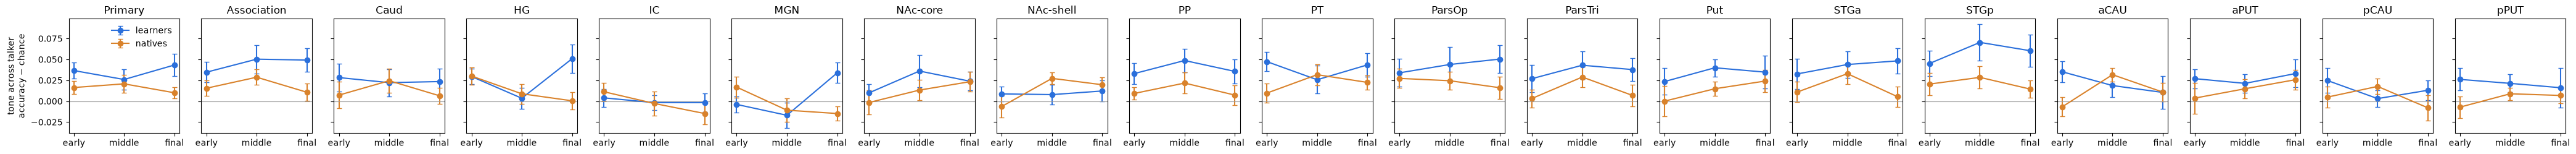

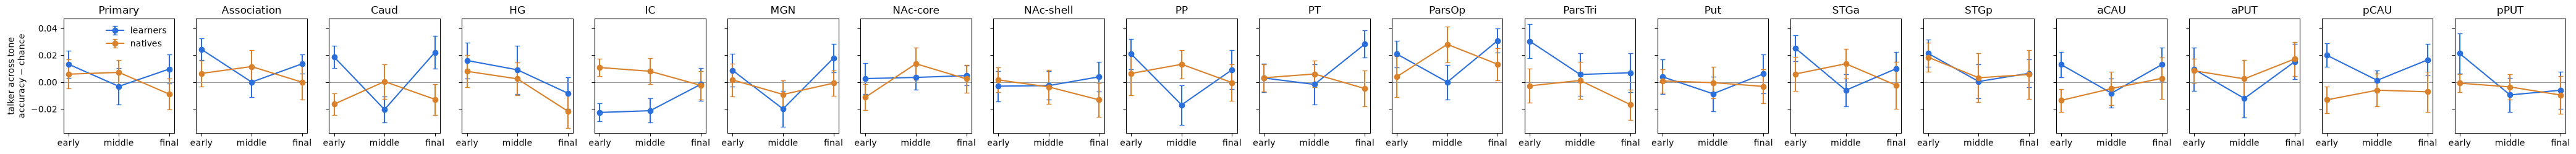

In [3]:
bilat = gs.bilateral_mean(dec)
regions = list(mvd.COMPOSITES) + sorted(r for r in bilat.region.unique() if r not in mvd.COMPOSITES)
for analysis in ANALYSES:
    sub = bilat[bilat.contrast == analysis]
    fig, axes = plt.subplots(1, len(regions), figsize=(2.2 * len(regions), 2.6), sharey=True)
    for ax, region in zip(np.atleast_1d(axes), regions):
        for group in gs.GROUPS:
            g = sub[(sub.region == region) & (sub.participant_group == group)].groupby('learning_stage').beta
            ax.errorbar(range(3), g.mean().reindex(gs.STAGE_ORDER), yerr=g.sem().reindex(gs.STAGE_ORDER),
                        marker='o', capsize=3, color=colors[group], label=labels[group])
        ax.axhline(0, color='0.6', lw=0.8)
        ax.set_xticks(range(3), gs.STAGE_ORDER)
        ax.set_title(region)
    np.atleast_1d(axes)[0].set_ylabel(f'{analysis.replace("_", " ")}\naccuracy − chance')
    np.atleast_1d(axes)[0].legend(frameon=False)
    fig.tight_layout()

## 3. Above chance within each group

One-sample t on accuracy − chance, per stage and stages averaged; FDR across regions within group × analysis × network (× stage).

In [4]:
above = gs.baseline_tests(dec)
above_by_stage = gs.baseline_tests(dec, by_stage=True)
above.to_csv(os.path.join(out_dir, 'above-chance.tsv'), sep='\t', index=False)
above_by_stage.to_csv(os.path.join(out_dir, 'above-chance_by-stage.tsv'), sep='\t', index=False)
above_by_stage[above_by_stage.contrast.isin(ANALYSES)].pivot_table(
    index=['contrast', 'network', 'region'], columns=['participant_group', 'learning_stage'], values='t').round(2)

participant_group                                 Mandarin              non-Mandarin             
learning_stage                                       early final middle        early final middle
contrast           network            region                                                     
talker_across_tone auditory           HG              0.67 -1.76   0.20         1.22 -0.70   0.50
                                      PP              0.40 -0.03   1.26         1.83  0.63  -1.15
                                      PT              0.32 -0.36   0.61         0.29  2.79  -0.12
                                      ParsOp          0.26  1.09   2.12         2.14  3.42  -0.00
                                      ParsTri        -0.22 -1.51   0.09         2.37  0.48   0.36
                                      STGa            0.48 -0.14   1.23         2.64  0.82  -0.51
                                      STGp            1.70  0.31   0.18         2.10  0.63   0.03
                   auditory-composite Association     0.66 -0.01   0.95         3.08  1.90  -0.00
                                      Primary         0.54 -0.77   0.78         1.32  0.89  -0.23
                   striatum-whole     Caud           -2.03 -1.12   0.03         2.28  1.81  -2.15
                                      Put             0.09 -0.26  -0.03         0.31  0.42  -0.67
                   subcort-aud        IC              1.67 -0.23   0.83        -3.41 -0.14  -2.37
                                      MGN             0.13 -0.09  -0.86         0.71  1.66  -1.50
                   tian-S2            NAc-core       -1.15  0.23   1.12         0.22  0.65   0.38
                                      NAc-shell       0.17 -1.05  -0.28        -0.27  0.36  -0.25
                                      aCAU           -1.61  0.18  -0.39         1.40  1.04  -0.76
                                      aPUT            0.93  1.37   0.17         0.60  1.17  -0.86
                                      pCAU           -1.34 -0.48  -0.49         2.27  1.40   0.17
                                      pPUT           -0.12 -0.69  -0.39         1.42 -0.44  -0.76
tone_across_talker auditory           HG              2.88  0.04   0.74         3.12  2.98   0.27
                                      PP              1.26  0.61   1.72         2.63  2.47   3.40
                                      PT              0.85  2.61   2.55         4.12  3.07   1.54
                                      ParsOp          2.35  1.22   2.24         2.02  3.06   2.09
                                      ParsTri         0.30  0.53   2.40         1.64  2.81   2.55
                                      STGa            0.88  0.43   2.65         1.80  3.18   2.73
                                      STGp            1.57  1.42   2.14         3.04  3.15   3.19
                   auditory-composite Association     1.66  1.04   3.08         2.81  3.55   2.95
                                      Primary         2.16  1.46   1.88         3.85  3.31   2.11
                   striatum-whole     Caud            0.46  0.65   1.69         1.72  1.49   1.35
                                      Put            -0.00  1.81   1.72         1.46  1.76   3.84
                   subcort-aud        IC              1.05 -1.14  -0.19         0.36 -0.16  -0.20
                                      MGN             1.33 -1.77  -0.77        -0.40  2.76  -1.14
                   tian-S2            NAc-core       -0.11  1.98   1.08         0.95  2.13   1.88
                                      NAc-shell      -0.50  2.14   3.81         0.97  0.96   0.66
                                      aCAU           -0.60  0.98   3.85         2.81  0.53   1.31
                                      aPUT            0.19  2.16   1.29         2.37  1.98   1.94
                                      pCAU            0.38 -0.53   1.88         1.67  1.09   0.30
                                      pPUT           -0.56  0.71   1.18         

## 4. Does a talker-invariant tone code emerge with learning? Trend, learners vs. natives

Full battery on the composites, aCAU and aPUT; Welch/permutation with FDR for every region.

In [5]:
trends = gs.subject_trends(dec)
focus = [r for r in list(mvd.COMPOSITES) + ['aCAU', 'aPUT'] if r in set(trends.region)]
battery = pd.concat([gs.trend_group_difference(trends, analysis, region, n_perms=n_perms, n_boot=n_boot, seed=seed)
                     for analysis in ANALYSES for region in focus], ignore_index=True)
battery.to_csv(os.path.join(out_dir, 'trend_focus-regions.tsv'), sep='\t', index=False)
per_region = dec[~dec.region.isin(mvd.COMPOSITES)]
trend_diff = gs.trend_difference_tests(gs.subject_trends(per_region), contrasts=ANALYSES, n_perms=n_perms, seed=seed)
trend_diff.to_csv(os.path.join(out_dir, 'trend_group-difference.tsv'), sep='\t', index=False)
battery.round(3)

,test,n,estimate,t,p,permutation_p,loso_preserved,ci_lower,ci_upper,contrast,region
0,non-Mandarin trend vs 0,12,0.007,0.451,0.661,0.665,0/12,-0.021,0.034,tone_across_talker,Primary
1,Mandarin trend vs 0,13,-0.006,-0.519,0.613,0.618,0/13,-0.030,0.016,tone_across_talker,Primary
2,non-Mandarin - Mandarin (Welch),25,0.013,0.677,0.505,0.509,0/25,-0.023,0.048,tone_across_talker,Primary
3,non-Mandarin trend vs 0,12,0.015,0.746,0.472,0.462,0/12,-0.022,0.051,tone_across_talker,Association
4,Mandarin trend vs 0,13,-0.005,-0.327,0.749,0.746,0/13,-0.033,0.023,tone_across_talker,Association
5,non-Mandarin - Mandarin (Welch),25,0.019,0.792,0.437,0.427,0/25,-0.027,0.065,tone_across_talker,Association
6,non-Mandarin trend vs 0,12,-0.025,-1.043,0.319,0.327,0/12,-0.067,0.021,tone_across_talker,aCAU
7,Mandarin trend vs 0,13,0.018,1.033,0.322,0.333,0/13,-0.014,0.050,tone_across_talker,aCAU
8,non-Mandarin - Mandarin (Welch),25,-0.042,-1.450,0.162,0.163,1/25,-0.098,0.013,tone_across_talker,aCAU
9,non-Mandarin trend vs 0,12,0.006,0.258,0.801,0.811,0/12,-0.038,0.049,tone_across_talker,aPUT


## 5. Natives ahead early? Group difference per stage

In [6]:
stage_diff = gs.group_difference_tests(per_region, contrasts=ANALYSES, by_stage=True, n_perms=n_perms, seed=seed)
stage_diff.to_csv(os.path.join(out_dir, 'group-difference_by-stage.tsv'), sep='\t', index=False)
stage_diff.pivot_table(index=['contrast', 'network', 'region'], columns='learning_stage', values='d')[list(gs.STAGE_ORDER)].round(2)

learning_stage                               early  middle  final
contrast           network        region                         
talker_across_tone auditory       HG          0.18    0.13   0.31
                                  PP          0.29   -0.68   0.19
                                  PT         -0.00   -0.18   0.79
                                  ParsOp      0.36   -0.61   0.46
                                  ParsTri     0.74    0.09   0.53
                                  STGa        0.48   -0.48   0.23
                                  STGp        0.08   -0.05   0.02
                   striatum-whole Caud        1.22   -0.51   0.84
                                  Put         0.08   -0.19   0.20
                   subcort-aud    IC         -1.44   -0.89   0.02
                                  MGN         0.16   -0.25   0.53
                   tian-S2        NAc-core    0.37   -0.26   0.07
                                  NAc-shell  -0.13    0.02   0.41
                                  aCAU        0.85   -0.08   0.20
                                  aPUT        0.03   -0.29  -0.04
                                  pCAU        1.00    0.20   0.49
                                  pPUT        0.55   -0.15   0.07
tone_across_talker auditory       HG         -0.02   -0.12   1.03
                                  PP          0.67    0.57   0.61
                                  PT          0.93   -0.12   0.52
                                  ParsOp      0.13    0.34   0.66
                                  ParsTri     0.49    0.28   0.67
                                  STGa        0.40    0.22   0.89
                                  STGp        0.50    0.66   0.87
                   striatum-whole Caud        0.37   -0.04   0.37
                                  Put         0.39    0.75   0.18
                   subcort-aud    IC         -0.19    0.02   0.31
                                  MGN        -0.51   -0.12   1.33
                   tian-S2        NAc-core    0.25    0.41   0.02
                                  NAc-shell   0.38   -0.58  -0.19
                                  aCAU        1.00   -0.32  -0.01
                                  aPUT        0.42    0.16   0.15
                                  pCAU        0.41   -0.42   0.43
                                  pPUT        0.72    0.39   0.15

## 6. Sensitivity: held-out run

Only if FLT2 ran with `--hold_out_run`. For natives, accuracy should hold up when the test run differs; a large drop points to run-specific (non-generalizing) structure. For learners a drop is expected early.

In [7]:
held = [c for c in dec.contrast.unique() if c.endswith('_held-out-run')]
if held:
    both = gs.bilateral_mean(dec[dec.contrast.isin(ANALYSES + held)])
    both['scheme'] = np.where(both.contrast.str.endswith('_held-out-run'), 'held-out-run', 'same-runs')
    both['analysis'] = both.contrast.str.replace('_held-out-run', '')
    print(both.pivot_table(index=['analysis', 'participant_group', 'learning_stage'], columns='scheme',
                           values='beta', aggfunc='mean').round(3))
else:
    print('no held-out-run results (rerun FLT2 decoding with --hold_out_run)')

scheme                                               held-out-run  same-runs
analysis           participant_group learning_stage                         
talker_across_tone Mandarin          early                 -0.006      0.001
                                     final                  0.003     -0.003
                                     middle                 0.009      0.004
                   non-Mandarin      early                  0.005      0.013
                                     final                  0.000      0.010
                                     middle                 0.004     -0.006
tone_across_talker Mandarin          early                  0.000      0.009
                                     final                  0.003      0.009
                                     middle                 0.010      0.019
                   non-Mandarin      early                 -0.000      0.026
                                     final                  0.011      0.033

## 7. Outcome decoding: do trial patterns carry correct vs. wrong?

FLT2 `decoding_outcome.py`: per ROI and stage, a class-weighted linear SVM separates correct from wrong trials (balanced accuracy; chance 0.5), with one talker held out per fold. The multivariate counterpart of the univariate `fbcorrectvswrong` contrast. The beta covers the whole trial (feedback follows the sound by one TR), so the signal can be feedback, response, or confidence.

Three centerings (mean pattern removed within run × group, separately in training and test sets):
- **stimulus** (main): only within-stimulus trial-to-trial differences, so stimulus difficulty can't drive it;
- **response**: within response key, so the button press alone can't (tone can);
- **none**: run mean only, for comparison (inflated by stimulus difficulty; on simulated null data ~0.53).

Predictions from the univariate result: above chance in aCAU for learners, declining across stages. Natives rarely err, so most have too few wrong trials (< 4 per stage) for a test; their rows are mostly missing.

In [8]:
outcome_dir = os.path.join(mvd.DERIV_DIR, mvd.GLMSINGLE_DIRNAME, 'decoding_outcome')
CENTERS = ['stimulus', 'response', 'none']
outcome = pd.concat([mvd.add_composites(mvd.load_outcome_decoding(outcome_dir, participants, c)) for c in CENTERS],
                    ignore_index=True)

# who has enough correct and wrong trials, by group x stage (trial counts are the same in every ROI)
counts = (outcome[(outcome.contrast == 'outcome_center-stimulus') & outcome.n_wrong.notna()]
          .groupby(['participant_group', 'learning_stage', 'participant_id'])[['n_correct', 'n_wrong']].first())
print('participants with enough trials, and their median correct / wrong counts:')
print(counts.groupby(['participant_group', 'learning_stage']).agg(
    n=('n_wrong', 'size'), correct=('n_correct', 'median'), wrong=('n_wrong', 'median'))
      .unstack('participant_group').reindex(gs.STAGE_ORDER))

participants with enough trials, and their median correct / wrong counts:
                         n               correct                 wrong             
participant_group Mandarin non-Mandarin Mandarin non-Mandarin Mandarin non-Mandarin
learning_stage                                                                     
early                    6           12     85.0         41.5      7.0         48.0
middle                   2           11     90.5         68.0      4.5         27.0
final                    1           11     88.0         83.0      8.0         11.0


In [9]:
# above chance, per group x centering (stages averaged, then by stage); FDR across regions
# within group x centering x network (x stage). Focus: composites and striatum
outcome_focus = [r for r in list(mvd.COMPOSITES) + ['aCAU', 'pCAU', 'aPUT', 'pPUT'] if r in set(outcome.region)]
outcome_above = gs.baseline_tests(outcome)
outcome_above_by_stage = gs.baseline_tests(outcome, by_stage=True)
outcome_above.to_csv(os.path.join(out_dir, 'outcome_above-chance.tsv'), sep='\t', index=False)
outcome_above_by_stage.to_csv(os.path.join(out_dir, 'outcome_above-chance_by-stage.tsv'), sep='\t', index=False)
cols = [c for c in ['participant_group', 'contrast', 'region', 'learning_stage', 'n', 'mean', 't', 'p', 'q']
        if c in outcome_above_by_stage]
print('stages averaged:')
print(outcome_above[outcome_above.region.isin(outcome_focus)][[c for c in cols if c != 'learning_stage']]
      .round(3).to_string(index=False))
outcome_above_by_stage[outcome_above_by_stage.region.isin(outcome_focus)
                       & (outcome_above_by_stage.participant_group == 'non-Mandarin')][cols].round(3)

/ix1/bchandrasekaran/krs228/software/miniconda3/envs/py3/lib/python3.14/site-packages/scipy/stats/_stats_py.py:1227: RuntimeWarning: divide by zero encountered in divide
  var *= (n / (n-ddof))  # to avoid error on division by zero
/ix1/bchandrasekaran/krs228/software/miniconda3/envs/py3/lib/python3.14/site-packages/scipy/stats/_stats_py.py:1227: RuntimeWarning: invalid value encountered in multiply
  var *= (n / (n-ddof))  # to avoid error on division by zero
/ix1/bchandrasekaran/krs228/software/miniconda3/envs/py3/lib/python3.14/site-packages/numpy/_core/_methods.py:219: RuntimeWarning: Degrees of freedom <= 0 for slice
  ret = _var(a, axis=axis, dtype=dtype, out=out, ddof=ddof,
/ix1/bchandrasekaran/krs228/software/miniconda3/envs/py3/lib/python3.14/site-packages/numpy/_core/_methods.py:211: RuntimeWarning: invalid value encountered in scalar divide
  ret = ret.dtype.type(ret / rcount)


stages averaged:
participant_group                contrast      region  n   mean      t     p     q
         Mandarin     outcome_center-none Association  7 -0.018 -0.935 0.386 0.386
         Mandarin     outcome_center-none     Primary  7 -0.030 -2.525 0.045 0.090
     non-Mandarin     outcome_center-none Association 12  0.025  2.942 0.013 0.027
     non-Mandarin     outcome_center-none     Primary 12  0.001  0.170 0.868 0.868
         Mandarin outcome_center-response Association  7  0.002  0.116 0.911 0.911
         Mandarin outcome_center-response     Primary  7 -0.004 -0.369 0.725 0.911
     non-Mandarin outcome_center-response Association 12  0.005  0.921 0.377 0.377
     non-Mandarin outcome_center-response     Primary 12 -0.005 -1.206 0.253 0.377
         Mandarin outcome_center-stimulus Association  7 -0.019 -2.784 0.032 0.032
         Mandarin outcome_center-stimulus     Primary  7 -0.021 -2.811 0.031 0.032
     non-Mandarin outcome_center-stimulus Association 12 -0.006 -1.027

,participant_group,contrast,region,learning_stage,n,mean,t,p,q
132,non-Mandarin,outcome_center-none,Association,early,12,0.016,1.073,0.306,0.612
133,non-Mandarin,outcome_center-none,Association,final,11,0.004,0.258,0.801,0.801
134,non-Mandarin,outcome_center-none,Association,middle,11,0.055,3.426,0.006,0.013
135,non-Mandarin,outcome_center-none,Primary,early,12,0.003,0.215,0.834,0.834
136,non-Mandarin,outcome_center-none,Primary,final,11,-0.014,-1.560,0.150,0.300
137,non-Mandarin,outcome_center-none,Primary,middle,11,0.014,1.506,0.163,0.163
144,non-Mandarin,outcome_center-response,Association,early,12,0.017,1.337,0.208,0.416
145,non-Mandarin,outcome_center-response,Association,final,11,-0.010,-1.725,0.115,0.115
146,non-Mandarin,outcome_center-response,Association,middle,11,0.008,1.270,0.233,0.466
147,non-Mandarin,outcome_center-response,Primary,early,12,0.006,0.798,0.442,0.442


In [10]:
# learners: does outcome information decline across stages (as the univariate aCAU contrast does)?
# Per-learner [-1, 0, 1] trend, stimulus centering; learners missing a stage (too few errors late) drop out
sys.path.insert(0, '..')
import resampling_stats as rs

learner_outcome = outcome[(outcome.participant_group == 'non-Mandarin')]
outcome_trends = gs.subject_trends(learner_outcome)
rng = np.random.default_rng(seed)
rows = []
for center in CENTERS:
    for region in outcome_focus:
        v = outcome_trends[(outcome_trends.contrast == f'outcome_center-{center}')
                           & (outcome_trends.region == region)].trend.dropna().values
        if len(v) < 3:
            continue
        loso = rs.leave_one_out_stability(v)
        boot = rs.bootstrap_ci(v, n_boot=n_boot, rng=rng)
        rows.append({'center': center, 'region': region, 'n': len(v), 'trend': v.mean(),
                     't': loso['original_t'], 'p': loso['original_p'],
                     'permutation_p': rs.exact_sign_flip_permutation_test(v)['p_value'],
                     'loso_preserved': f"{loso['n_preserved']}/{loso['n_folds']}",
                     'ci_lower': boot['ci_lower'], 'ci_upper': boot['ci_upper']})
outcome_learner_trends = pd.DataFrame(rows)
outcome_learner_trends.to_csv(os.path.join(out_dir, 'outcome_learner-trends.tsv'), sep='\t', index=False)
outcome_learner_trends.round(3)

,center,region,n,trend,t,p,permutation_p,loso_preserved,ci_lower,ci_upper
0,stimulus,Primary,10,0.016,1.498,0.168,0.178,1/10,-0.004,0.035
1,stimulus,Association,10,-0.005,-0.254,0.805,0.793,0/10,-0.041,0.029
2,stimulus,aCAU,10,-0.001,-0.060,0.953,0.957,0/10,-0.034,0.034
3,stimulus,pCAU,10,-0.015,-1.631,0.137,0.131,1/10,-0.031,0.003
4,stimulus,aPUT,10,0.018,1.034,0.328,0.361,0/10,-0.013,0.051
5,stimulus,pPUT,10,-0.001,-0.122,0.906,0.900,0/10,-0.022,0.016
6,response,Primary,10,-0.026,-2.805,0.021,0.021,10/10,-0.043,-0.009
7,response,Association,10,-0.034,-1.891,0.091,0.080,1/10,-0.069,-0.002
8,response,aCAU,10,-0.020,-1.372,0.203,0.262,0/10,-0.050,0.004
9,response,pCAU,10,-0.032,-2.036,0.072,0.070,2/10,-0.060,-0.003


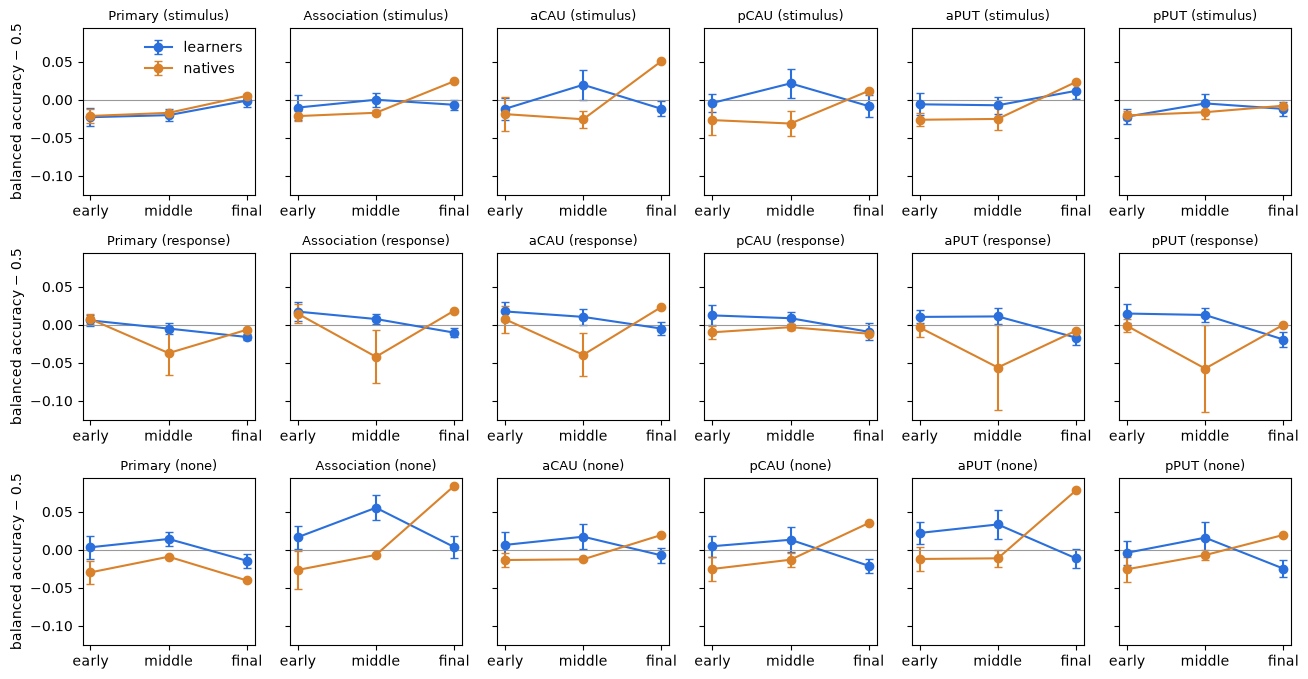

In [11]:
bilat_outcome = gs.bilateral_mean(outcome)
fig, axes = plt.subplots(len(CENTERS), len(outcome_focus), figsize=(2.2 * len(outcome_focus), 2.3 * len(CENTERS)), sharey=True)
for row, center in zip(np.atleast_2d(axes), CENTERS):
    sub = bilat_outcome[bilat_outcome.contrast == f'outcome_center-{center}']
    for ax, region in zip(row, outcome_focus):
        for group in gs.GROUPS:
            g = sub[(sub.region == region) & (sub.participant_group == group)].groupby('learning_stage').beta
            ax.errorbar(range(3), g.mean().reindex(gs.STAGE_ORDER), yerr=g.sem().reindex(gs.STAGE_ORDER),
                        marker='o', capsize=3, color=colors[group], label=labels[group])
        ax.axhline(0, color='0.6', lw=0.8)
        ax.set_xticks(range(3), gs.STAGE_ORDER)
        ax.set_title(f'{region} ({center})', fontsize=9)
    row[0].set_ylabel('balanced accuracy − 0.5')
np.atleast_2d(axes)[0, 0].legend(frameon=False)
fig.tight_layout()

## 8. Export

In [12]:
dec.to_csv(os.path.join(out_dir, 'decoding.tsv'), sep='\t', index=False)
trends.to_csv(os.path.join(out_dir, 'trend_scalars.tsv'), sep='\t', index=False)
print('wrote', out_dir)

wrote /ix1/bchandrasekaran/krs228/data/FLT/data_denoised/derivatives/glmsingle_fmriprep-25.2.5_space-T1w/stats_two-group/decoding_generalization
